# Evaluation Rare Postural Transition Recognition

This notebook is the evaluation companion to [Improving Rare Postural Transitions.ipynb](Improving%20Rare%20Postural%20Transitions.ipynb), referred to below as the **main notebook**. The main notebook contains the model implementations and experiments. This report presents their recorded results, explains the controlled comparisons, and adds the metrics and error analyses recoverable from saved outputs. It does not train models, rerun model selection or refit preprocessing.

**Primary metric:** macro-F1 over transition classes 7–12. Transition macro-recall is an additional evaluation measure. Common-class F1, all-class macro metrics, accuracy and recorded runtime show the wider trade-offs. **Recorded** identifies results read from the main notebook; **Derived** identifies arithmetic or analysis added here. Each code cell produces exactly one table or one figure. Captions, sources and interpretations are written in Markdown.

**Reading order:** 1. protocol and data → 2. baselines → 3. controlled improvements → 4. context length → 5. PCA → 6. final comparison → 7. class/instance-level errors → 8. research answers and remaining evidence gaps.

The official test participants were inspected during development. Their scores are **descriptive, not an untouched final estimate**. The future-window configurations are offline methods. These limitations apply throughout the report.


## 1. Evaluation protocol and data

### 1.1 Read recorded source results

The main notebook is read as a data file. Result tables are located by their variable names or exact column headers; saved diagnostic tables are located by their output headers. The report does not execute the main notebook's code. Source positions in Appendix A are discovered at runtime, so inserting or moving a cell does not invalidate a fixed index.

**Table 1 — Loaded source-table groups.** This setup step only collects the recorded results and their provenance. It is separate from the CSV loading, result alignment and display helpers in section 1.2. Ambiguous or missing result tables produce an explicit error instead of selecting an arbitrary match.


In [1]:
# Read recorded source results; no main-notebook code is executed.
from pathlib import Path
import ast
import base64
import hashlib
import io
import json
import re
import pandas as pd
from IPython.display import display, Image

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "our approach" / "Improving Rare Postural Transitions.ipynb").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Keep both notebooks in 'our approach' and run there or from the project root.")
MAIN_PATH = PROJECT_ROOT / "our approach" / "Improving Rare Postural Transitions.ipynb"
DATA_DIR = PROJECT_ROOT / "our approach" / "wrangled data"
main_bytes = MAIN_PATH.read_bytes()
main_notebook = json.loads(main_bytes)
source_sha256 = hashlib.sha256(main_bytes).hexdigest()

def collect_source_results(notebook):
    cells, assignments, registry, locations = notebook["cells"], {}, [], {}
    for index, cell in enumerate(cells):
        if cell["cell_type"] != "code":
            continue
        for statement in ast.parse("".join(cell["source"])).body:
            if isinstance(statement, ast.Assign):
                for target in statement.targets:
                    if isinstance(target, ast.Name):
                        assignments.setdefault(target.id, []).append((index, statement.value))

    def assignment(name):
        matches = assignments.get(name, [])
        if len(matches) != 1:
            raise ValueError(f"Expected one source assignment for {name}; found {len(matches)}.")
        return matches[0]

    def literal(node):
        if isinstance(node, ast.Name):
            return literal(assignment(node.id)[1])
        if isinstance(node, (ast.List, ast.Tuple)):
            return [literal(item) for item in node.elts]
        if isinstance(node, ast.Dict):
            return {literal(k): literal(v) for k, v in zip(node.keys, node.values)}
        return ast.literal_eval(node)

    def register(key, label, index, kind, frame):
        registry.append([label, str(index), kind, len(frame)])
        locations[key] = index
        return frame

    def literal_table(variable, label):
        index, call = assignment(variable)
        if not isinstance(call, ast.Call) or not isinstance(call.func, ast.Attribute) or call.func.attr != "DataFrame":
            raise ValueError(f"Expected a literal DataFrame constructor for {variable}.")
        kwargs = {k.arg: literal(k.value) for k in call.keywords}
        frame = pd.DataFrame(literal(call.args[0]), **kwargs)
        return register(variable, label, index, "Recorded literal table", frame)

    markdown_tables = []
    for index, cell in enumerate(cells):
        if cell["cell_type"] != "markdown":
            continue
        block = []
        for line in "".join(cell["source"]).splitlines() + [""]:
            if line.startswith("|"):
                block.append([item.strip() for item in line.split("|")[1:-1]])
            elif block:
                if len(block) >= 2:
                    markdown_tables.append((index, pd.DataFrame(block[2:], columns=block[0])))
                block = []

    def markdown_table(key, columns, label):
        matches = [(i, frame) for i, frame in markdown_tables if list(frame.columns) == columns]
        if len(matches) != 1:
            raise ValueError(f"Expected one Markdown table for {label}; found {len(matches)}.")
        index, frame = matches[0]
        return register(key, label, index, "Recorded Markdown table", frame)

    def output_table(key, columns, label):
        matches = []
        for index, cell in enumerate(cells):
            for output in cell.get("outputs", []):
                value = output.get("data", {}).get("text/plain", "")
                value = "".join(value) if isinstance(value, list) else value
                if value.strip() and value.lstrip().splitlines()[0].split() == columns:
                    frame = pd.read_csv(io.StringIO(value), sep=r"\s+", index_col=0).reset_index(drop=True)
                    matches.append((index, frame))
        if len(matches) != 1:
            raise ValueError(f"Expected one saved output table for {label}; found {len(matches)}.")
        index, frame = matches[0]
        return register(key, label, index, "Recorded output table", frame)

    specs = [
        ("validation_ablation", "Weight/context ablation"), ("past_only_folds", "Previous-window LR folds"),
        ("oversampling", "ROS comparison"), ("rf_ros_confirmation", "RF ROS split repeats"),
        ("recorded_window_cv", "Context-length validation"), ("lr_length_validation", "LR repeat summaries"),
        ("pca_benchmark", "PCA/raw benchmark"), ("paired_timing", "Paired runtime measurements")]
    results = {variable: literal_table(variable, label) for variable, label in specs}
    schemas = [
        ("baseline_test", ["Model", "Test common F1", "Test transition F1", "Test accuracy"], "Single-window test scores"),
        ("context_test", ["Model", "Transition F1 change", "Common F1 change"], "Unweighted three-window test changes"),
        ("final_test", ["Model", "Final input", "Validation transition F1", "Test transition F1", "Test transition recall",
                        "Test common F1", "Test macro F1", "Test accuracy"], "Final configuration test comparison"),
        ("mlp_class", ["Class ID", "Activity", "Correct / test support", "Class accuracy"], "Final MLP correct counts")]
    for key, columns, label in schemas:
        results[key] = markdown_table(key, columns, label)
    results["lr_report"] = output_table("lr_report", ["activity_id", "support", "precision", "recall", "f1"], "Raw seven-window LR class report")
    results["lr_cases"] = output_table("lr_cases", ["test_row", "participant", "actual", "predicted"], "All LR transition error instances")
    diagnostic_index = locations["lr_report"]
    if locations["lr_cases"] != diagnostic_index:
        raise ValueError("LR class report and error instances come from different source cells.")
    outputs = cells[diagnostic_index].get("outputs", [])
    summaries, images = [], []
    required_scores = {"accuracy", "transition_f1", "transition_recall", "common_f1"}
    for output in outputs:
        image = output.get("data", {}).get("image/png")
        if image:
            images.append("".join(image) if isinstance(image, list) else image)
        value = output.get("text", "")
        value = "".join(value) if isinstance(value, list) else value
        for line in value.splitlines():
            try:
                candidate = ast.literal_eval(line.strip())
            except (SyntaxError, ValueError):
                continue
            if isinstance(candidate, dict) and required_scores.issubset(candidate):
                summaries.append(candidate)
    if len(summaries) != 1 or len(images) != 1:
        raise ValueError("The saved LR diagnostic needs one score summary and one count-matrix image.")
    results["lr_summary"], results["lr_image_png"] = summaries[0], base64.b64decode(images[0])
    final_text = "".join(cells[locations["final_test"]]["source"])
    aggregate_patterns = {
        "mlp_all_recorded": r"macro precision/recall/F1 are \*\*([\d.]+) / ([\d.]+) / ([\d.]+)\*\*",
        "mlp_transition_recorded": r"For transitions alone, precision/recall/F1 are \*\*([\d.]+) / ([\d.]+) / ([\d.]+)\*\*"}
    for key, pattern in aggregate_patterns.items():
        match = re.search(pattern, final_text)
        if match is None:
            raise ValueError(f"Review the changed final-model text before extracting {key}.")
        results[key] = tuple(map(float, match.groups()))
    return results, registry

source_results, source_registry = collect_source_results(main_notebook)
loaded_sources = pd.DataFrame(source_registry, columns=["Evidence", "Main cell (0-based)", "Saved form", "Rows"])
display(loaded_sources.groupby("Saved form", sort=False).size().rename("Result tables loaded").to_frame())


,Result tables loaded
Saved form,
Recorded literal table,8
Recorded Markdown table,4
Recorded output table,2


### 1.2 Load metadata and prepare evaluation helpers

Each observation is a 2.56-second sensor window with 561 engineered features. Activity labels and participant IDs are metadata, not predictors. The source keeps the official training/test participant split and uses three-fold participant-grouped validation within the training participants. Original scaling, PCA and resampling are fitted or applied only on the training side of each fold.

**Table 2 — Dataset summary.** This second setup step loads CSV metadata, aligns the recorded model rows, defines the ordinary pandas table helper and checks class supports/participant separation. It does not construct features or fit models. Both setup inputs are collapsed by default; their result tables remain visible.


In [2]:
# CSV metadata, result alignment and display helpers are separate from source parsing.
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COLORS = {"blue": "#335c81", "orange": "#d08842", "green": "#4b8a80", "muted": "#aab5bd"}
LABELS = np.arange(1, 13)
MODEL_ORDER = ["logreg", "linear_svm", "random_forest", "xgboost", "mlp"]
MODEL_NAMES = {"logreg": "Logistic regression", "linear_svm": "Linear SVM", "random_forest": "Random forest",
               "xgboost": "XGBoost", "mlp": "MLP + memory"}
MODEL_ALIASES = {value: key for key, value in MODEL_NAMES.items()}
MODEL_ALIASES.update({"MLP + posture memory": "mlp", "MLP (15 epochs + memory)": "mlp"})

def align_models(frame):
    result = frame.copy()
    result["model"] = result.Model.map(MODEL_ALIASES)
    if result.model.isna().any() or result.model.duplicated().any() or set(result.model) != set(MODEL_ORDER):
        raise ValueError("Expected one recorded row for each of the five model families.")
    return result.drop(columns="Model").set_index("model").reindex(MODEL_ORDER)

def show_table(frame, decimals=4, *, formats=None):
    rounding = decimals if formats is None else {
        column: formats.get(column, decimals) for column in frame.select_dtypes(include="floating").columns}
    display(frame.round(rounding))

ablation = align_models(source_results["validation_ablation"])
past_folds = source_results["past_only_folds"].copy()
ros = align_models(source_results["oversampling"])
rf_ros_repeats = source_results["rf_ros_confirmation"].copy()
window_cv = source_results["recorded_window_cv"].copy()
lr_repeats = source_results["lr_length_validation"].copy()
pca, timing = (source_results[key].copy() for key in ["pca_benchmark", "paired_timing"])
baseline_test = align_models(source_results["baseline_test"]).astype(float)
baseline_test.columns = ["common_f1", "transition_f1", "accuracy"]
baseline_test["macro_f1_derived"] = (baseline_test.common_f1 + baseline_test.transition_f1) / 2
context_test = align_models(source_results["context_test"]).astype(float)
context_test.columns = ["transition_f1_change", "common_f1_change"]
final_raw = align_models(source_results["final_test"])
final_config = pd.DataFrame(index=MODEL_ORDER)
final_config["Windows"] = final_raw["Final input"].str.extract(r"(\d+)", expand=False).astype(int)
final_config["Context features"] = final_config.Windows * 561
final_config["Representation"] = final_raw["Final input"].map(lambda s: "PCA-" + re.search(r"PCA-(\d+)", s).group(1) if "PCA-" in s else "Raw")
final_config["Classifier inputs"] = [int(re.search(r"PCA-(\d+)", s).group(1)) if "PCA-" in s else int(final_config.loc[k, "Context features"])
                                     for k, s in final_raw["Final input"].items()]
final_test = final_raw.drop(columns="Final input").astype(float)
final_test.columns = ["validation_transition_f1", "transition_f1", "transition_recall", "common_f1", "macro_f1", "accuracy"]
mlp_class = source_results["mlp_class"].rename(columns={"Activity": "activity"}).copy()
mlp_class["class_id"] = mlp_class["Class ID"].astype(int)
mlp_class[["correct", "support"]] = mlp_class["Correct / test support"].str.split(" / ", expand=True).astype(int)
mlp_class["missed"], mlp_class["recall"] = mlp_class.support - mlp_class.correct, mlp_class.correct / mlp_class.support
mlp_class = mlp_class[["class_id", "activity", "correct", "support", "missed", "recall"]]
mlp_all_recorded, mlp_transition_recorded = (source_results[key] for key in ["mlp_all_recorded", "mlp_transition_recorded"])
lr_saved_report, lr_cases = (source_results[key].copy() for key in ["lr_report", "lr_cases"])
lr_saved_summary, lr_diagnostic_png = source_results["lr_summary"], source_results["lr_image_png"]

metadata_columns = ["subject_id", "activity_id", "activity_label"]
train_meta = pd.read_csv(DATA_DIR / "hapt_train.csv", usecols=metadata_columns)
test_meta = pd.read_csv(DATA_DIR / "hapt_test.csv", usecols=metadata_columns)
feature_count = len(pd.read_csv(DATA_DIR / "hapt_train.csv", nrows=0).columns) - len(metadata_columns)
if feature_count != 561 or set(train_meta.subject_id) & set(test_meta.subject_id):
    raise ValueError("Feature count or participant separation differs from the original setup.")
CLASS_NAMES = test_meta[["activity_id", "activity_label"]].drop_duplicates().set_index("activity_id").activity_label.reindex(LABELS).tolist()
class_lookup = pd.Series(CLASS_NAMES, index=LABELS)
y_test, test_subject = test_meta.activity_id.to_numpy(dtype=int), test_meta.subject_id.to_numpy(dtype=int)
expected_support = np.bincount(y_test, minlength=13)[1:]
if not np.array_equal(mlp_class.support, expected_support) or not np.array_equal(lr_saved_report.support, expected_support):
    raise ValueError("Saved class supports do not match the test metadata.")
for model, value in window_cv[window_cv.window.eq(3)].set_index("model").transition_f1.items():
    if abs(value - ablation.loc[model, "Three windows + weights"]) > 0.00005 + 1e-12:
        raise ValueError("Ablation and context-sweep starting points disagree beyond rounding.")
if not np.allclose(final_test.macro_f1, (final_test.common_f1 + final_test.transition_f1) / 2, atol=0.0001, rtol=0):
    raise ValueError("Final macro F1 differs from its two six-class means beyond rounding.")

dataset_summary = pd.DataFrame([
    ["Training", len(train_meta), train_meta.subject_id.nunique(), feature_count,
     int(train_meta.activity_id.ge(7).sum()), 100 * train_meta.activity_id.ge(7).mean()],
    ["Test", len(test_meta), test_meta.subject_id.nunique(), feature_count,
     int(test_meta.activity_id.ge(7).sum()), 100 * test_meta.activity_id.ge(7).mean()],
], columns=["Split", "Windows", "Participants", "Features", "Transition windows", "Transitions (%)"])
show_table(dataset_summary, decimals=2)


,Split,Windows,Participants,Features,Transition windows,Transitions (%)
0,Training,7767,21,561,352,4.53
1,Test,3162,9,561,166,5.25


### 1.3 Class imbalance and metric definitions

**Figure 1 — Training and test class counts.** Classes 1–6 dominate both splits. Only 352/7,767 training windows and 166/3,162 test windows are transitions, so high overall accuracy can coexist with poor transition recognition. The figure uses the original CSV metadata; no rows are resampled here.


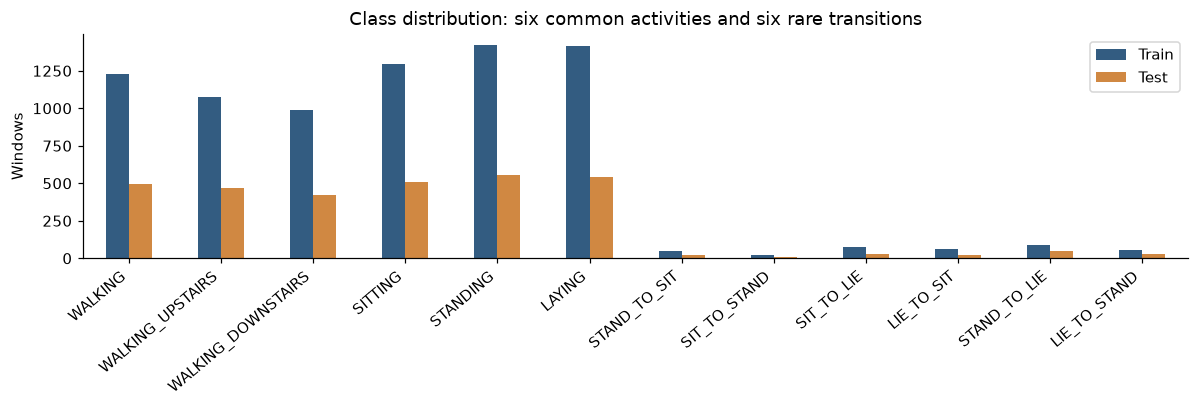

In [3]:
class_counts = pd.DataFrame({"Train": train_meta.activity_id.value_counts().reindex(LABELS, fill_value=0),
                             "Test": test_meta.activity_id.value_counts().reindex(LABELS, fill_value=0)}, index=LABELS)
ax = class_counts.set_axis(CLASS_NAMES).plot.bar(figsize=(11, 3.8), color=[COLORS["blue"], COLORS["orange"]])
ax.set(ylabel="Windows", xlabel="", title="Class distribution: six common activities and six rare transitions")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


For each class, precision measures how many predictions of that class are correct; recall measures how many true windows of that class are found. F1 balances those two quantities. **Macro scores average per-class scores equally**, rather than weighting them by support. Transition macro scores use classes 7–12, common macro scores use classes 1–6, and overall macro scores use all 12. Undefined scores use zero, matching the source.

A 0.01 score difference is **one percentage point (pp)**. Macro-F1 is the average of per-class F1 values; it is not generally the harmonic mean of macro-precision and macro-recall. The main notebook's “class accuracy” is **class recall**. Three-fold validation scores are averages across folds, whereas test scores use the official test windows; they should not be treated as the same evaluation.

## 2. Single-window baselines

### 2.1 Participant-grouped validation

All five baseline models use only the current window, no extra class weights and no ROS. The MLP retains its fixed eight-window posture-memory rule, so its baseline already includes that postprocessing. Model settings are those fixed in the main notebook.

**Table 3 — Recorded validation transition macro-F1.** Source: main notebook §1, `validation_ablation`. The rows use the same three participant-grouped folds. This establishes the starting point for the controlled changes in section 3.


In [4]:
show_table(ablation[["Baseline"]].rename(index=MODEL_NAMES, columns={"Baseline": "Validation transition F1"}))


,Validation transition F1
model,
Logistic regression,0.7433
Linear SVM,0.7367
Random forest,0.6411
XGBoost,0.6774
MLP + memory,0.7413


The single-window validation scores range from **0.6411 to 0.7433**. More complex model families do not automatically remove the rare-transition problem.

### 2.2 Descriptive test performance

**Table 4 — Single-window test scores.** Source: the main notebook's single-window test table. Common F1, transition F1 and accuracy are recorded. The final column is **derived** as `(common F1 + transition F1) / 2`, because the two groups each contain six classes; it inherits rounding from those inputs.


In [5]:
show_table(baseline_test.rename(index=MODEL_NAMES, columns={"common_f1": "Common F1", "transition_f1": "Transition F1",
    "accuracy": "Accuracy", "macro_f1_derived": "Macro F1 (derived)"}))


,Common F1,Transition F1,Accuracy,Macro F1 (derived)
model,,,,
Logistic regression,0.9514,0.7532,0.9386,0.8523
Linear SVM,0.9562,0.8112,0.9459,0.8837
Random forest,0.9207,0.7120,0.9105,0.8163
XGBoost,0.9437,0.7888,0.9358,0.8662
MLP + memory,0.9477,0.8607,0.9443,0.9042


Common-class test F1 is **0.9207–0.9562**, compared with transition F1 **0.7120–0.8607**. Accuracy alone hides much of this difference because transitions form only 5.25% of test windows. These test scores are descriptive; the validation results, not this table, support the recorded window-length choices.

## 3. Controlled comparisons of context, weighting and ROS

### 3.1 Separate context from weighting

**Table 5 — Recorded validation ablation.** Source: main notebook §1, `validation_ablation`. Within each model, folds and fixed settings remain the same. The four columns separate single-window training, weighting alone, three-window context alone, and their combination. No ROS is used in this table.


In [6]:
show_table(ablation.rename(index=MODEL_NAMES))


,Baseline,Weights only,Three windows only,Three windows + weights
model,,,,
Logistic regression,0.7433,0.7385,0.8540,0.8631
Linear SVM,0.7367,0.7451,0.8503,0.8649
Random forest,0.6411,0.6787,0.8131,0.8236
XGBoost,0.6774,0.7561,0.7954,0.8398
MLP + memory,0.7413,0.7577,0.8981,0.8661


**Figure 2 — Derived F1 changes from the single-window baseline.** Each bar subtracts that model's baseline score from the corresponding column in Table 5. This presents the size of each change on a common pp scale; it is not an additional experiment.


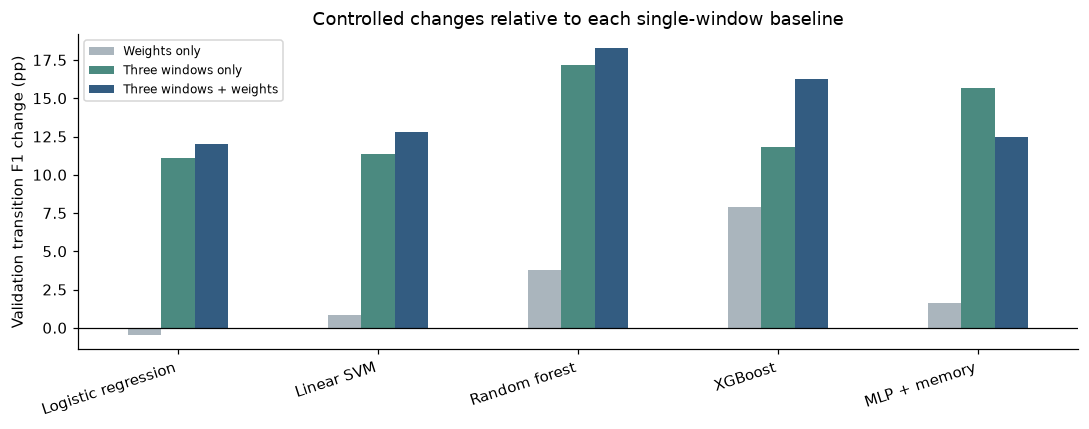

In [7]:
ablation_change_pp = 100 * ablation.drop(columns="Baseline").sub(ablation.Baseline, axis=0)
ax = ablation_change_pp.rename(index=MODEL_NAMES).plot.bar(figsize=(10, 4),
    color=[COLORS["muted"], COLORS["green"], COLORS["blue"]])
ax.axhline(0, color="black", linewidth=0.8)
ax.set(ylabel="Validation transition F1 change (pp)", xlabel="", title="Controlled changes relative to each single-window baseline")
plt.xticks(rotation=18, ha="right")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


Across the five model families, mean transition F1 rises from **0.7080** at baseline to **0.8422** with three windows alone. Weights alone reach **0.7352**. Context produces the clearest consistent gain. These are averages across five model families, not uncertainty estimates.

### 3.2 Isolated effect of class weighting

**Table 6 — Derived weighted-minus-unweighted changes.** The first column compares the first two columns of Table 5; the second compares its last two. Each comparison holds context fixed, so it isolates the recorded weighting change rather than mixing weighting with extra windows.


In [8]:
weighting_change_pp = pd.DataFrame({
    "Weighting effect: 1 window (pp)": 100 * (ablation["Weights only"] - ablation["Baseline"]),
    "Weighting effect: 3 windows (pp)": 100 * (ablation["Three windows + weights"] - ablation["Three windows only"]),
})
show_table(weighting_change_pp.rename(index=MODEL_NAMES), decimals=2)


,Weighting effect: 1 window (pp),Weighting effect: 3 windows (pp)
model,,
Logistic regression,-0.48,0.91
Linear SVM,0.84,1.46
Random forest,3.76,1.05
XGBoost,7.87,4.44
MLP + memory,1.64,-3.20


Weighting helps four models in each comparison, but the model that declines changes: single-window LR drops slightly, while three-window MLP drops **3.20 pp**. Weighting is therefore model-dependent. The source does not save complete matched transition-recall and common-F1 results for these conditions. **The table establishes the F1 changes, but cannot establish that weighting preserves common-activity performance.**

### 3.3 Previous-only context versus both neighbors

**Table 7 — LR context comparison without weighting or ROS.** Source: the recorded baseline/three-window scores and the three saved previous-window fold scores. The previous-window row is their derived arithmetic mean. This specific check was recorded for LR only.


In [9]:
previous_comparison = pd.DataFrame([
    ["Current window", ablation.loc["logreg", "Baseline"]],
    ["Previous + current", past_folds["Transition F1"].mean()],
    ["Previous + current + next", ablation.loc["logreg", "Three windows only"]],
], columns=["LR input", "Validation transition F1"])
show_table(previous_comparison)


,LR input,Validation transition F1
0,Current window,0.7433
1,Previous + current,0.7641
2,Previous + current + next,0.8540


LR improves from **0.7433 to 0.7641** with the preceding window, then reaches **0.8540** with both neighbors. The result supports bidirectional context in this offline comparison, but does not establish the same previous-only effect for the other model families.

### 3.4 Common-activity effects of adding three-window context

**Table 8 — Recorded descriptive test changes, converted to pp.** Source: main notebook §2, “What three full windows changed on the test set.” Both sides are unweighted and use no ROS. Only context changes, so the common-F1 column directly addresses the cost of adding context.


In [10]:
show_table((100 * context_test).rename(index=MODEL_NAMES, columns={"transition_f1_change": "Transition F1 change (pp)",
    "common_f1_change": "Common F1 change (pp)"}), decimals=2)


,Transition F1 change (pp),Common F1 change (pp)
model,,
Logistic regression,15.13,0.43
Linear SVM,7.06,1.32
Random forest,15.97,0.40
XGBoost,9.65,1.36
MLP + memory,6.44,1.29


Every model improves both transition and common F1 in this matched context comparison. This supports adding context without a measured common-class cost in these recorded test fits. It does **not** isolate class weighting.

**Table 9 — Derived absolute three-window test F1 scores.** Add Table 8's recorded changes to Table 4's baseline values, then average the two six-class means for overall macro-F1. These reconstructed scores inherit rounding from both source inputs; they are not newly computed predictions. Three-window test accuracy and recall cannot be reconstructed from these F1 scores.


In [11]:
three_window_test = baseline_test[["transition_f1", "common_f1"]] + context_test.rename(columns={
    "transition_f1_change": "transition_f1", "common_f1_change": "common_f1"})
three_window_test["macro_f1"] = (three_window_test.transition_f1 + three_window_test.common_f1) / 2
show_table(three_window_test.rename(index=MODEL_NAMES, columns={"transition_f1": "Transition F1",
    "common_f1": "Common F1", "macro_f1": "Macro F1 (derived)"}))


,Transition F1,Common F1,Macro F1 (derived)
model,,,
Logistic regression,0.9045,0.9557,0.9301
Linear SVM,0.8818,0.9694,0.9256
Random forest,0.8717,0.9247,0.8982
XGBoost,0.8853,0.9573,0.9213
MLP + memory,0.9251,0.9606,0.9428


### 3.5 Random oversampling after context and weighting

**Table 10 — Recorded ROS comparison.** Source: main notebook §2.4, `oversampling`. All conditions use three-window context and exponent-0.5 weighting. ROS duplicates transition-class training rows up to target 60 or 100 per fold; validation rows retain their natural prevalence. No resampling is performed by this report.


In [12]:
show_table(ros.rename(index=MODEL_NAMES))


,No ROS,ROS target 60,ROS target 100
model,,,
Logistic regression,0.8631,0.8641,0.8668
Linear SVM,0.8649,0.8669,0.8655
Random forest,0.8236,0.8373,0.8231
XGBoost,0.8398,0.8359,0.8192
MLP + memory,0.8661,0.8985,0.8868


ROS-60 raises MLP transition F1 from **0.8661 to 0.8985** (+3.24 pp). LR/SVM changes are small, RF improves in the original split, and XGBoost declines. ROS-100 is not consistently better. These findings apply to the recorded three-window configurations, not automatically to the longer final inputs.

**Table 11 — Recorded RF repeat summaries with derived pp differences.** The first three rows summarize three folds for split seeds 42, 123 and 2026; the last summarizes all nine paired folds. Source: `rf_ros_confirmation`. Common-F1 changes are available for this follow-up, allowing a direct performance trade-off check.


In [13]:
rf_ros_view = rf_ros_repeats.copy()
rf_ros_view["Transition change (pp)"] = 100 * (rf_ros_view["ROS 60 transition F1"] - rf_ros_view["No ROS transition F1"])
rf_ros_view["Common change (pp)"] = 100 * rf_ros_view.pop("Common F1 change")
show_table(rf_ros_view)


,Fold seed,No ROS transition F1,ROS 60 transition F1,Transition change (pp),Common change (pp)
0,42,0.8236,0.8373,1.37,-0.26
1,123,0.8576,0.8613,0.37,-0.41
2,2026,0.8238,0.8367,1.29,-0.20
3,All nine paired folds,0.8350,0.8451,1.01,-0.29


Across the nine paired folds, RF gains **1.01 pp** transition F1 while common F1 declines **0.29 pp**. This is a small measured trade-off for ROS, not for weighting alone. The repeat summaries reuse training participants and should not be treated as independent test sets.

## 4. Context length and validation stability

### 4.1 Extend the full temporal input

**Figure 3 — Recorded transition-F1 curves.** Source: main notebook §3, `recorded_window_cv`. Each panel varies the number of full windows while holding the main folds, model settings, weighting and no-ROS condition fixed. All inputs are raw context features with the original standardization and no PCA. Future and past windows are added symmetrically.


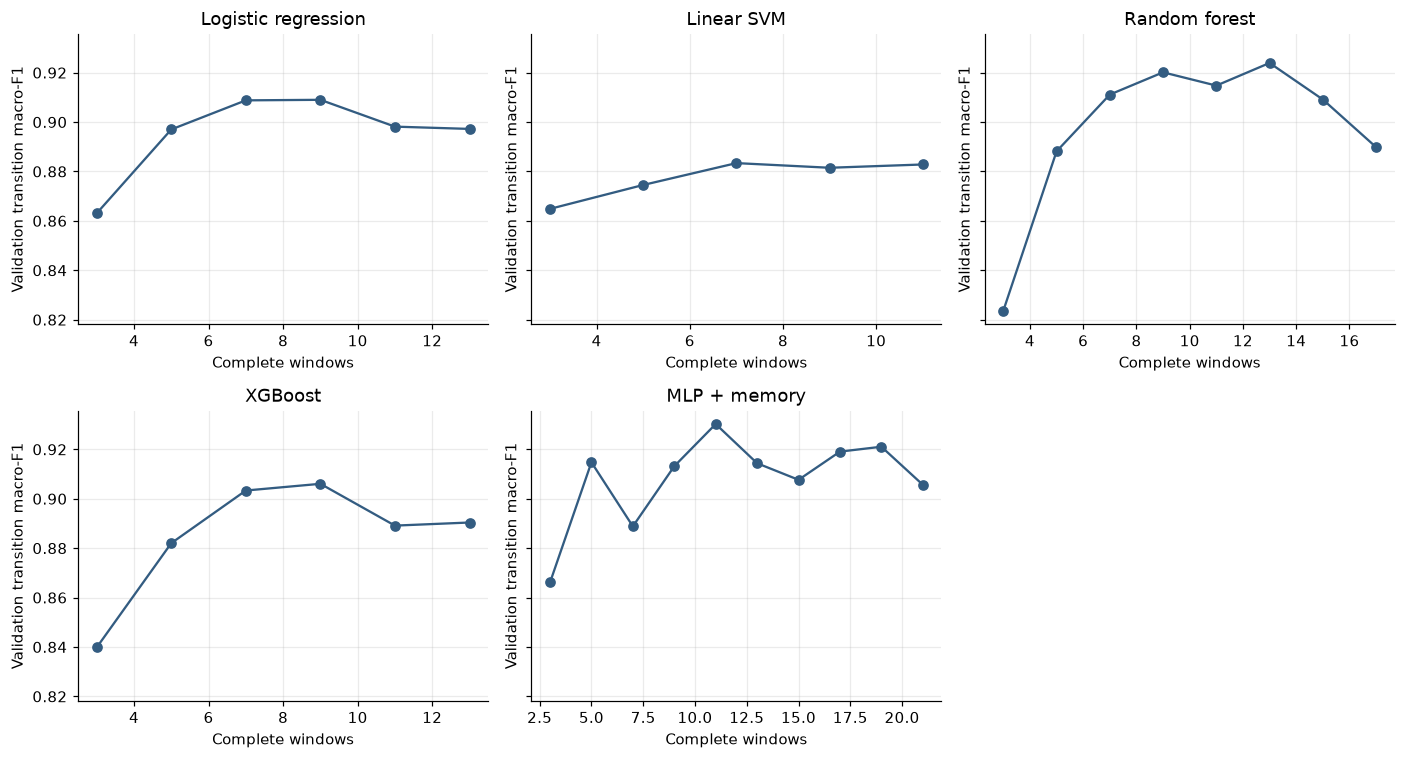

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, model in zip(axes.flat, MODEL_ORDER):
    rows = window_cv[window_cv.model.eq(model)]
    ax.plot(rows.window, rows.transition_f1, marker="o", color=COLORS["blue"])
    ax.set(title=MODEL_NAMES[model], xlabel="Complete windows", ylabel="Validation transition macro-F1")
    ax.grid(alpha=0.25)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()


All five models improve from three to five windows, but later changes fluctuate. More context can help identify the posture before and after a movement; it also increases feature count and delay. The curves support choosing practical near-peak lengths instead of assuming that longer inputs are always better.

### 4.2 Review the source's practical-length rule

**Table 12 — Derived selection from the recorded curves.** Choose the shortest measured length within **0.005** transition F1 of that model's peak, provided common F1 is no more than **0.01** below its three-window value. “Longer lengths checked” counts subsequent tested lengths; it is not a statistical plateau test.


In [15]:
length_rows = []
for model, rows in window_cv.groupby("model"):
    peak = rows.transition_f1.max()
    common_at_three = rows.loc[rows.window.eq(3), "common_f1"].iloc[0]
    eligible = rows[(peak - rows.transition_f1 <= 0.005) & (rows.common_f1 >= common_at_three - 0.01)]
    chosen = rows[rows.window.eq(eligible.window.min())].iloc[0]
    length_rows.append([model, int(chosen.window), peak, chosen.transition_f1, chosen.common_f1,
                        int(rows.window.gt(chosen.window).sum())])
length_selection = pd.DataFrame(length_rows, columns=["model", "Windows", "Peak transition F1", "Selected transition F1",
    "Selected common F1", "Longer lengths checked"]).set_index("model").reindex(MODEL_ORDER)
if not np.array_equal(length_selection.Windows, final_config.Windows):
    raise ValueError("The practical-length rule disagrees with the final source configurations.")
show_table(length_selection.rename(index=MODEL_NAMES))


,Windows,Peak transition F1,Selected transition F1,Selected common F1,Longer lengths checked
model,,,,,
Logistic regression,7,0.9090,0.9088,0.9414,3
Linear SVM,7,0.8834,0.8834,0.9448,2
Random forest,9,0.9239,0.9201,0.9158,4
XGBoost,7,0.9061,0.9033,0.9312,3
MLP + memory,11,0.9302,0.9302,0.9329,5


The selected lengths match the main notebook: **7** for LR/SVM/XGBoost, **9** for RF, and **11** for MLP. These are near-peak choices within the tested dataset/settings. LR's selected raw-input score here differs from its final PCA-400 validation score because the representation changes later.

### 4.3 Repeated LR validation summaries

**Figure 4 — Recorded mean ± fold standard deviation.** Source: main notebook §4, `lr_length_validation`. The summaries cover nine folds across three split seeds. Error bars are **fold SD, not confidence intervals**; participants recur across seeds.


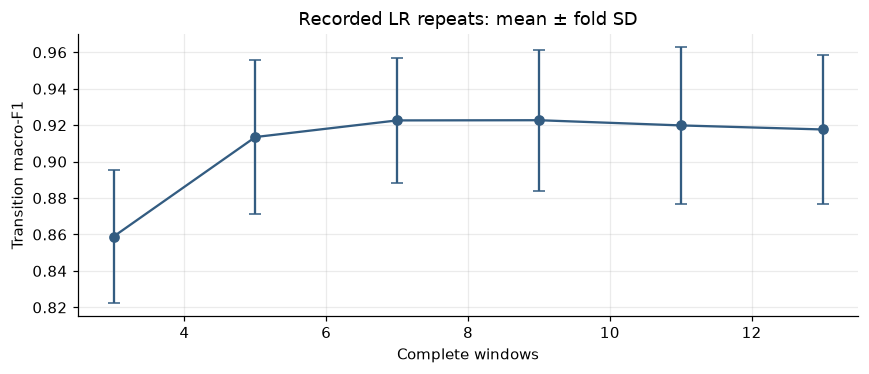

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(lr_repeats.window, lr_repeats.transition_f1_mean, yerr=lr_repeats.transition_f1_sd,
            fmt="o-", capsize=4, color=COLORS["blue"])
ax.set(xlabel="Complete windows", ylabel="Transition macro-F1", title="Recorded LR repeats: mean ± fold SD")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


Seven and nine LR windows are nearly level: mean transition F1 **0.922613 versus 0.922719**. This is consistent with selecting the shorter near-peak input. The summaries describe variability in reused training participants; equivalent repeated final-configuration evidence is not saved for every model.

## 5. PCA performance and computation trade-offs

### 5.1 Recorded quality and runtime

**Table 13 — Recorded PCA/raw measurements.** Source: main notebook §5, `pca_benchmark`. Each model uses its selected context length. “Raw” means no PCA, while the original standardization remains. Fold time includes scaling, PCA when used, fitting and prediction in the original experiment; it excludes loading and shared context construction. This report runs no timing benchmark.


In [17]:
pca_view = pca[["model", "representation", "transition_f1", "common_f1", "mean_seconds_per_fold"]].copy()
pca_view["model"] = pca_view.model.map(MODEL_NAMES)
pca_view = pca_view.rename(columns={"model": "Model", "representation": "Representation", "transition_f1": "Transition F1",
    "common_f1": "Common F1", "mean_seconds_per_fold": "Seconds/fold"})
show_table(pca_view)


,Model,Representation,Transition F1,Common F1,Seconds/fold
0,Logistic regression,raw,0.9088,0.9414,8.4148
1,Logistic regression,pca200,0.9022,0.9288,5.6587
2,Logistic regression,pca400,0.9048,0.9372,5.1143
3,Logistic regression,pca500,0.9090,0.9384,8.9205
4,Random forest,raw,0.9201,0.9158,50.3278
5,Random forest,pca200,0.7751,0.8857,16.5596
6,Random forest,pca500,0.6778,0.8812,32.4642
7,XGBoost,raw,0.9033,0.9312,381.0929
8,XGBoost,pca200,0.8029,0.8880,29.5112
9,XGBoost,pca500,0.8224,0.8956,73.2859


A useful speed/quality result must lower recorded runtime while losing no more than **0.005** in either transition or common F1. Missing SVM raw time is shown as `NaN`; it must not be treated as zero or used to claim a speedup.

**Figure 5 — Derived PCA trade-off relative to each model's raw input.** The horizontal axis is percentage time saved; the vertical axis is transition-F1 change in pp. The −0.5 pp line is the transition-quality tolerance. Common-F1 tolerance must also be checked in Table 13, so a point's position alone does not establish a useful speedup.


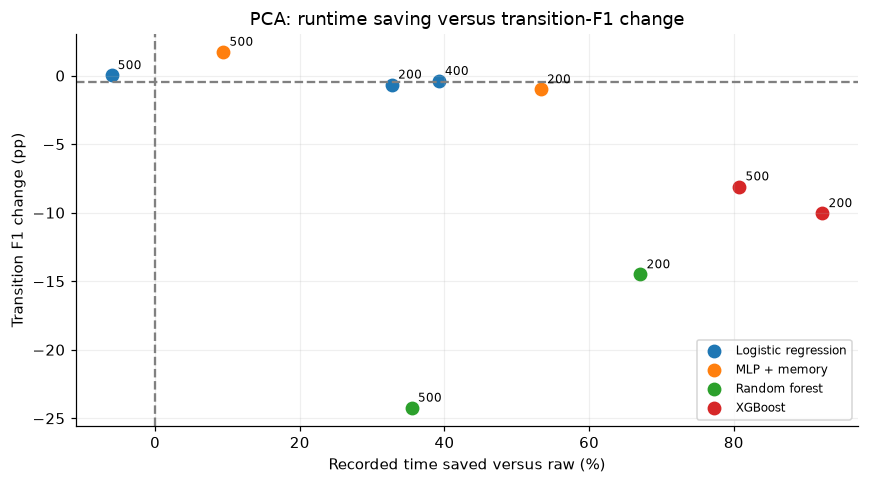

In [18]:
pca_raw = pca[pca.representation.eq("raw")].set_index("model")
pca["transition_change_pp"] = 100 * (pca.transition_f1 - pca.model.map(pca_raw.transition_f1))
pca["common_change_pp"] = 100 * (pca.common_f1 - pca.model.map(pca_raw.common_f1))
pca["time_saved_pct"] = 100 * (1 - pca.mean_seconds_per_fold / pca.model.map(pca_raw.mean_seconds_per_fold))
fig, ax = plt.subplots(figsize=(8, 4.5))
for model, rows in pca[pca.representation.ne("raw") & pca.time_saved_pct.notna()].groupby("model"):
    ax.scatter(rows.time_saved_pct, rows.transition_change_pp, s=65, label=MODEL_NAMES[model])
    for row in rows.itertuples():
        ax.annotate(row.representation.replace("pca", ""), (row.time_saved_pct, row.transition_change_pp),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.axhline(-0.5, color="gray", linestyle="--")
ax.axvline(0, color="gray", linestyle="--")
ax.set(xlabel="Recorded time saved versus raw (%)", ylabel="Transition F1 change (pp)",
       title="PCA: runtime saving versus transition-F1 change")
ax.grid(alpha=0.2)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


RF/XGBoost PCA reduces runtime but loses substantial transition F1. LR PCA-400 stays within both F1 tolerances. MLP PCA-500 improves the saved F1 scores, so its computation claim needs the paired timing evidence below rather than a quality-only conclusion.

### 5.2 Paired timing repetitions

**Table 14 — Recorded paired timings and derived time savings.** Source: `paired_timing`. Each row compares raw and PCA on the same original folds/machine for that repetition. Positive time saved means faster PCA; negative means slower PCA. The two repetitions should not be pooled as if their absolute runtimes were identical.


In [19]:
paired_timing = timing.copy()
paired_timing["Time saved (%)"] = 100 * (1 - paired_timing["PCA s/fold"] / paired_timing["Raw s/fold"])
show_table(paired_timing, decimals=2)


,Model,Representation,Run,Raw s/fold,PCA s/fold,Time saved (%)
0,Logistic regression,PCA-400,1,2.73,1.97,27.94
1,Logistic regression,PCA-400,2,8.41,5.11,39.22
2,MLP,PCA-500,1,20.86,18.90,9.44
3,MLP,PCA-500,2,16.54,19.01,-14.89


LR PCA-400 saves about **28–39%** in both repetitions while meeting the F1 tolerances. MLP PCA-500 is faster in one repetition and slower in the other. Together with the SVM timing/quality limits, this supports the source's decision to use PCA-400 only for final LR and retain raw features for the other four final models.

## 6. Final configurations and descriptive test comparison

### 6.1 Identify the exact configurations

**Table 15 — Final input configurations from the main notebook §6.** All five use mild exponent-0.5 weighting and no ROS. Fixed within-model hyperparameters remain those in the main implementation. The MLP trains for 15 epochs in the original experiments and retains posture memory. Context feature count is before PCA; classifier inputs are after PCA where present.


In [20]:
show_table(final_config.rename(index=MODEL_NAMES))


,Windows,Context features,Representation,Classifier inputs
Logistic regression,7,3927,PCA-400,400
Linear SVM,7,3927,Raw,3927
Random forest,9,5049,Raw,5049
XGBoost,7,3927,Raw,3927
MLP + memory,11,6171,Raw,6171


### 6.2 Recorded validation and test scores

**Table 16 — Final recorded scores.** Source: the main notebook's final comparison. The first column is training-participant validation; the remaining columns are the one recorded full-training refit evaluated on the official test windows. The different split types are labelled explicitly. This report does not refit those configurations.


In [21]:
show_table(final_test.rename(index=MODEL_NAMES, columns={"validation_transition_f1": "CV transition F1",
    "transition_f1": "Test transition F1", "transition_recall": "Test transition recall", "common_f1": "Test common F1",
    "macro_f1": "Test macro F1", "accuracy": "Test accuracy"}))


,CV transition F1,Test transition F1,Test transition recall,Test common F1,Test macro F1,Test accuracy
model,,,,,,
Logistic regression,0.9048,0.9373,0.9311,0.9615,0.9494,0.9592
Linear SVM,0.8834,0.9322,0.9205,0.9784,0.9553,0.9741
Random forest,0.9201,0.9296,0.9046,0.9344,0.9320,0.9345
XGBoost,0.9033,0.9285,0.9387,0.9696,0.9491,0.9681
MLP + memory,0.9302,0.9716,0.9552,0.9766,0.9741,0.9756


The **11-window MLP + memory** leads the matched final validation comparison with transition F1 **0.9302**. Its recorded test transition F1 is **0.9716**, common F1 **0.9766**, and accuracy **0.9756**. This is the main notebook's practical final selection; it does not claim the largest score across every exploratory PCA configuration or a general winner established by the inspected test set.

### 6.3 Compare final configurations with single-window baselines

**Figure 6 — Recorded descriptive test comparison.** Baselines come from Table 4 and final scores from Table 16. Each panel uses the same F1 axis. Context, weighting and sometimes PCA change together, so these differences show the combined configurations' outcomes rather than an isolated weighting effect.


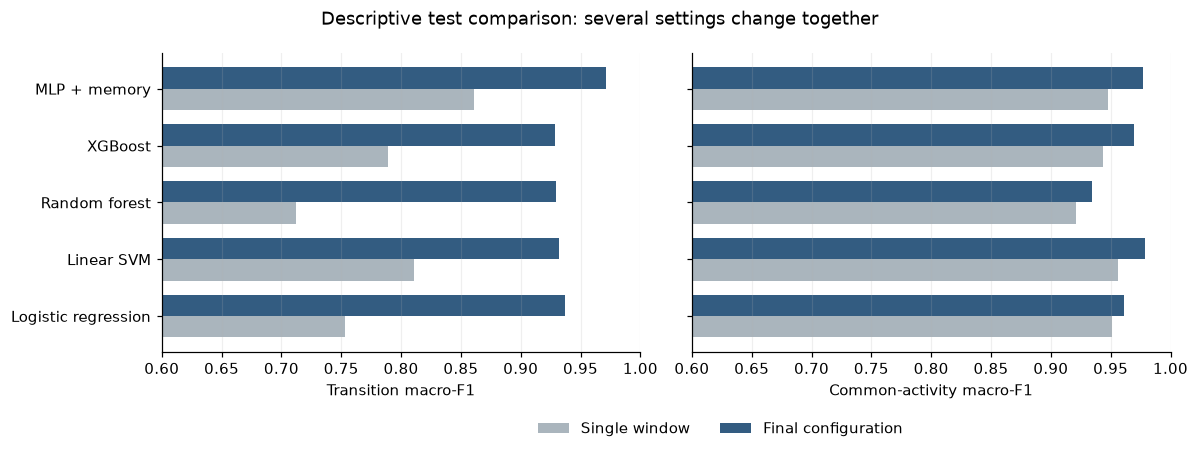

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, metric, title in zip(axes, ["transition_f1", "common_f1"], ["Transition macro-F1", "Common-activity macro-F1"]):
    pd.DataFrame({"Single window": baseline_test[metric], "Final configuration": final_test[metric]}).rename(index=MODEL_NAMES).plot.barh(
        ax=ax, color=[COLORS["muted"], COLORS["blue"]], width=0.75)
    ax.set(xlim=(0.6, 1.0), xlabel=title, ylabel="")
    ax.get_legend().remove()
    ax.grid(axis="x", alpha=0.2)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.6, -0.02), frameon=False)
fig.suptitle("Descriptive test comparison: several settings change together")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()


Both transition and common F1 rise for every final configuration relative to its recorded single-window baseline. This is consistent with the combined approach improving the observed task, but the isolated contribution of each change must be taken from the controlled experiments in section 3.

## 7. Class-level and instance-level evaluation

### 7.1 Final MLP: class recall and missed windows

**Table 17 — Recorded integer class counts with derived recall.** Source: main notebook §6, “Best MLP: test accuracy for each class.” The model is the final **11-window raw-feature MLP with weighting and posture memory**. Recall is correct/support; missed is support−correct. Per-class precision/F1 are not shown because their false-positive counts were not saved.


In [23]:
mlp_class_view = mlp_class[["class_id", "activity", "correct", "support", "missed"]].copy()
mlp_class_view["Recall (%)"] = 100 * mlp_class.recall
show_table(mlp_class_view.rename(columns={"class_id": "Class", "activity": "Activity", "correct": "Correct",
    "support": "Support", "missed": "Missed"}), decimals=2)


,Class,Activity,Correct,Support,Missed,Recall (%)
0,1,WALKING,491,496,5,98.99
1,2,WALKING_UPSTAIRS,467,471,4,99.15
2,3,WALKING_DOWNSTAIRS,415,420,5,98.81
3,4,SITTING,475,508,33,93.50
4,5,STANDING,535,556,21,96.22
5,6,LAYING,544,545,1,99.82
6,7,STAND_TO_SIT,20,23,3,86.96
7,8,SIT_TO_STAND,10,10,0,100.00
8,9,SIT_TO_LIE,32,32,0,100.00
9,10,LIE_TO_SIT,24,25,1,96.00


**Table 18 — Newly recovered exact accuracy and macro-recalls.** Every derived value below uses the integer counts in Table 17. The source column is the main notebook's rounded score where available; the missing common-recall entry is an actual reporting gap filled here, not a zero score.


In [24]:
mlp_recovered = pd.DataFrame([
    ["Accuracy", mlp_class.correct.sum() / mlp_class.support.sum(), final_test.loc["mlp", "accuracy"]],
    ["All-class macro-recall", mlp_class.recall.mean(), mlp_all_recorded[1]],
    ["Transition macro-recall", mlp_class.loc[mlp_class.class_id.ge(7), "recall"].mean(), mlp_transition_recorded[1]],
    ["Common macro-recall", mlp_class.loc[mlp_class.class_id.le(6), "recall"].mean(), np.nan],
], columns=["Metric", "Derived from integer counts", "Source rounded score"])
for row in mlp_recovered.dropna().itertuples(index=False, name=None):
    if abs(row[1] - row[2]) > 0.00005 + 1e-12:
        raise ValueError("A count-derived MLP score disagrees with its reported rounded value.")
show_table(mlp_recovered, decimals=6)


,Metric,Derived from integer counts,Source rounded score
0,Accuracy,0.975648,0.9756
1,All-class macro-recall,0.966355,0.9664
2,Transition macro-recall,0.955217,0.9552
3,Common macro-recall,0.977493,NaN


The exact all-class macro-recall is **0.966355**, transition macro-recall **0.955217**, and common macro-recall **0.977493**. Accuracy is **3,085/3,162 = 0.975648**. These improve the precision of the evaluation report without adding any new fitted-model results.

**Table 19 — MLP aggregate precision, recall and F1 by scope.** All-class and transition macro-precision/F1 are recorded in the source text. Common F1 is recorded in the final table; common macro-precision is **derived from rounded means** as `2 × overall precision − transition precision`, because each group has six classes. Recalls come from exact counts. This recovers group-level precision, not the missing per-class precision values.


In [25]:
mlp_common_precision_derived = 2 * mlp_all_recorded[0] - mlp_transition_recorded[0]
mlp_aggregate = pd.DataFrame([
    ["All 12 classes", mlp_all_recorded[0], mlp_class.recall.mean(), mlp_all_recorded[2]],
    ["Common 1–6 (precision derived)", mlp_common_precision_derived, mlp_class.recall.iloc[:6].mean(), final_test.loc["mlp", "common_f1"]],
    ["Transitions 7–12", mlp_transition_recorded[0], mlp_class.recall.iloc[6:].mean(), mlp_transition_recorded[2]],
], columns=["Scope", "Macro precision", "Macro recall", "Macro F1"])
show_table(mlp_aggregate, formats={"Macro recall": 6})


,Scope,Macro precision,Macro recall,Macro F1
0,All 12 classes,0.9828,0.966355,0.9741
1,Common 1–6 (precision derived),0.9758,0.977493,0.9766
2,Transitions 7–12,0.9898,0.955217,0.9716


**Figure 7 — Final MLP transition-class recall.** This visualizes the six transition rows from Table 17. The 80–101% axis highlights their differences; it is labelled and does not represent counts or precision.


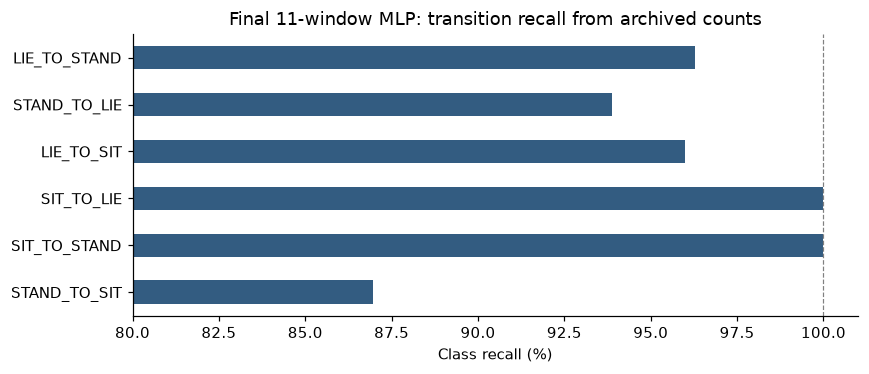

In [26]:
mlp_transition = mlp_class[mlp_class.class_id.ge(7)].set_index("activity")
ax = (100 * mlp_transition.recall).plot.barh(figsize=(8, 3.5), color=COLORS["blue"])
ax.set(xlim=(80, 101), xlabel="Class recall (%)", ylabel="", title="Final 11-window MLP: transition recall from archived counts")
ax.axvline(100, color="gray", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.show()


The MLP misses **8 of 166** transition windows. Stand-to-sit has the lowest transition recall (**20/23 = 86.96%**). Sit-to-stand and sit-to-lie reach 100% recall on only 10 and 32 test windows. Neither their precision nor the destinations of the eight missed transitions can be inferred from these correct counts.

### 7.2 Raw seven-window LR diagnostic: complete class metrics

The next analyses concern the **weighted, raw-feature seven-window LR reference**, not the final PCA-400 LR or the final MLP. They use its saved per-class report and complete transition-error list. For each class, the code requires a unique integer correct count and prediction count compatible with the four-decimal recall/precision and known support. If the rounded report is insufficient for unique recovery, execution stops instead of assuming exact counts.

The recovered counts are checked against all saved class F1 values and the four exact summary scores. The 12-class count image is displayed directly from the source, with no byte-fingerprint dependency. Only the six true-transition rows are reconstructed as a matrix, because their complete error instances and supports determine every destination exactly.

**Table 20 — Derived LR macro metrics.** Unique integer count recovery gives the same exact class/aggregate metrics as the saved report, without transcribing a complete matrix from image pixels. All-class and common precision/recall supplement the main notebook's selected-score printout. This LR reference's accuracy is **0.966477**.


In [27]:
def recover_class_totals(report, total_windows):
    correct, predicted = [], []
    tolerance = 0.5e-4 + 1e-12  # Source precision/recall are rounded to four decimals.
    for row in report.itertuples(index=False):
        support = int(row.support)
        candidates = np.arange(support + 1)
        matches = candidates[np.abs(candidates / support - row.recall) <= tolerance]
        if len(matches) != 1:
            raise ValueError("The rounded LR recall does not uniquely identify its correct count.")
        tp = int(matches[0])
        candidates = np.arange(max(tp, 1), total_windows + 1)
        matches = candidates[np.abs(tp / candidates - row.precision) <= tolerance]
        if len(matches) != 1:
            raise ValueError("The rounded LR precision does not uniquely identify its prediction count.")
        correct.append(tp)
        predicted.append(int(matches[0]))
    return np.array(correct), np.array(predicted)

if not np.array_equal(lr_saved_report.activity_id.to_numpy(), LABELS):
    raise ValueError("LR class-report order must match class IDs 1–12.")
lr_correct, lr_predicted_totals = recover_class_totals(lr_saved_report, len(test_meta))
if lr_predicted_totals.sum() != len(test_meta):
    raise ValueError("Recovered class prediction counts do not cover all test windows.")
lr_precision, lr_recall = lr_correct / lr_predicted_totals, lr_correct / expected_support
lr_f1 = 2 * lr_correct / (expected_support + lr_predicted_totals)
lr_class = pd.DataFrame({"Class": LABELS, "Activity": CLASS_NAMES, "Support": expected_support,
                         "Precision": lr_precision, "Recall": lr_recall, "F1": lr_f1})
lr_summary = {"accuracy": float(lr_correct.sum() / len(test_meta))}
for prefix, region in [("macro", slice(None)), ("common", slice(0, 6)), ("transition", slice(6, 12))]:
    for metric, values in [("precision", lr_precision), ("recall", lr_recall), ("f1", lr_f1)]:
        lr_summary[f"{prefix}_{metric}"] = float(values[region].mean())
for metric, value in lr_saved_summary.items():
    if not np.isclose(lr_summary[metric], value, atol=1e-12, rtol=0):
        raise ValueError(f"Recovered LR {metric} differs from its saved exact score.")
for current, saved in [("Precision", "precision"), ("Recall", "recall"), ("F1", "f1")]:
    if not np.allclose(lr_class[current].round(4), lr_saved_report[saved], atol=1e-12, rtol=0):
        raise ValueError(f"Recovered LR {current} differs from its saved class report.")

if len(lr_cases) != int((expected_support - lr_correct)[6:].sum()) or lr_cases.test_row.duplicated().any():
    raise ValueError("The saved transition-error list is incomplete or duplicated.")
case_rows = lr_cases.test_row.to_numpy(dtype=int)
if ((case_rows < 0).any() or (case_rows >= len(test_meta)).any()
        or not np.array_equal(y_test[case_rows], lr_cases.actual)
        or not np.array_equal(test_subject[case_rows], lr_cases.participant)
        or not lr_cases.actual.between(7, 12).all() or not lr_cases.predicted.between(1, 12).all()
        or (lr_cases.actual == lr_cases.predicted).any()):
    raise ValueError("Saved LR error instances do not match valid misclassified transition rows.")
lr_transition_cm = np.zeros((6, 12), dtype=int)
np.add.at(lr_transition_cm, (lr_cases.actual.to_numpy() - 7, lr_cases.predicted.to_numpy() - 1), 1)
for row in range(6):
    lr_transition_cm[row, row + 6] = expected_support[row + 6] - lr_transition_cm[row].sum()
if not np.array_equal(np.diag(lr_transition_cm[:, 6:]), lr_correct[6:]):
    raise ValueError("Transition cases disagree with the recovered per-class correct counts.")

lr_macro = pd.DataFrame([
    ["All 12 classes", lr_summary["macro_precision"], lr_summary["macro_recall"], lr_summary["macro_f1"]],
    ["Common 1–6", lr_summary["common_precision"], lr_summary["common_recall"], lr_summary["common_f1"]],
    ["Transitions 7–12", lr_summary["transition_precision"], lr_summary["transition_recall"], lr_summary["transition_f1"]],
], columns=["Scope", "Macro precision", "Macro recall", "Macro F1"])
show_table(lr_macro, decimals=6)


,Scope,Macro precision,Macro recall,Macro F1
0,All 12 classes,0.955070,0.947575,0.950501
1,Common 1–6,0.970018,0.969666,0.969597
2,Transitions 7–12,0.940123,0.925484,0.931405


**Table 21 — LR per-class report from the archived counts.** Precision includes false positives from all 12 classes, including common activities predicted as transitions. Support is the number of true test windows. Values are displayed to four decimals to match the main report, while calculations retain full precision.


In [28]:
show_table(lr_class)


,Class,Activity,Support,Precision,Recall,F1
0,1,WALKING,496,0.9821,0.9960,0.9890
1,2,WALKING_UPSTAIRS,471,0.9729,0.9915,0.9821
2,3,WALKING_DOWNSTAIRS,420,0.9926,0.9643,0.9783
3,4,SITTING,508,0.9566,0.9114,0.9335
4,5,STANDING,556,0.9195,0.9658,0.9421
5,6,LAYING,545,0.9963,0.9890,0.9926
6,7,STAND_TO_SIT,23,1.0000,0.9565,0.9778
7,8,SIT_TO_STAND,10,0.9091,1.0000,0.9524
8,9,SIT_TO_LIE,32,0.9286,0.8125,0.8667
9,10,LIE_TO_SIT,25,0.9231,0.9600,0.9412


### 7.3 Full recorded confusion and normalized transition outcomes

**Figure 8 — Recorded 12-class LR count matrix.** This is the image saved by the raw seven-window LR diagnostic in the main notebook. It is located alongside the matching class report and error list, then displayed directly. Rows are true classes and columns are predictions. The image's original “Selected model” title refers to this LR diagnostic, not the final MLP or PCA-400 LR configuration.


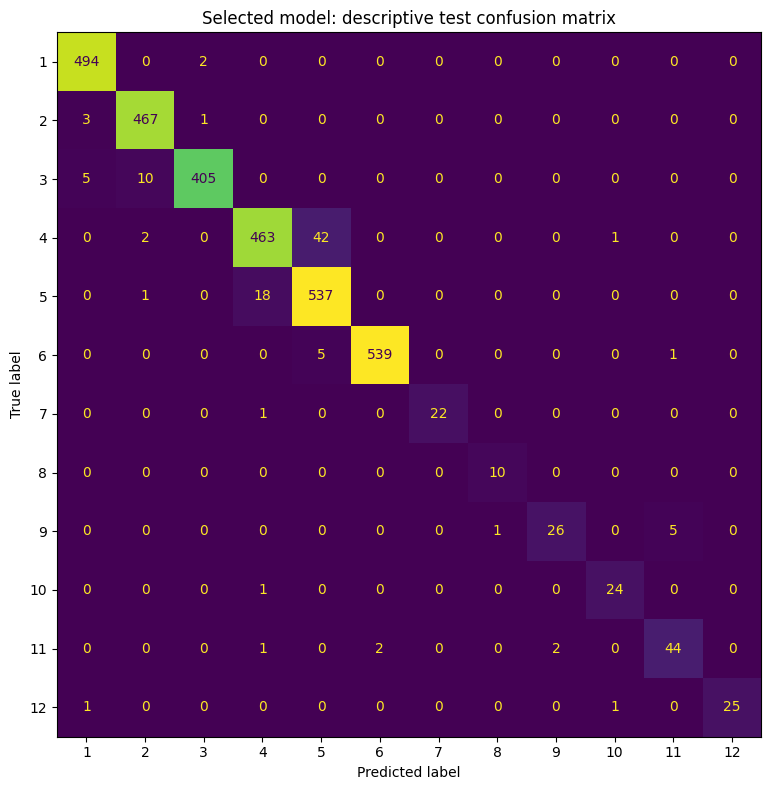

In [29]:
display(Image(data=lr_diagnostic_png))


**Figure 9 — Derived normalized true-transition rows.** The complete saved transition-error list and class supports recover all six rows for true classes 7–12, including correct diagonals and predictions into any class 1–12. Each row is divided by its true-class support and sums to one. Common-class rows cannot be reconstructed uniquely from class metrics alone; their full recorded counts remain visible in Figure 8.


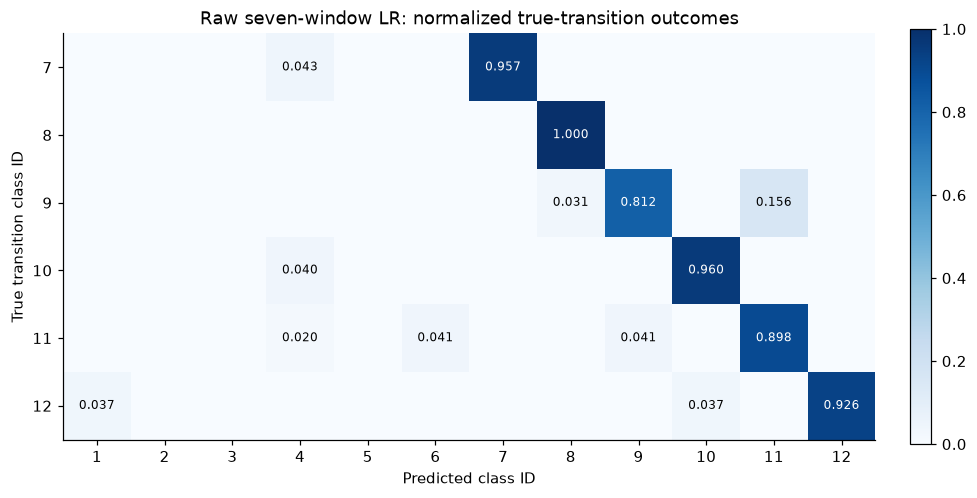

In [30]:
lr_transition_normalized = lr_transition_cm / expected_support[6:, None]
fig, ax = plt.subplots(figsize=(9, 4.5))
im = ax.imshow(lr_transition_normalized, vmin=0, vmax=1, cmap="Blues")
for i in range(6):
    for j in range(12):
        if lr_transition_cm[i, j]:
            ax.text(j, i, f"{lr_transition_normalized[i, j]:.3f}", ha="center", va="center", fontsize=8,
                    color="white" if lr_transition_normalized[i, j] > 0.5 else "black")
ax.set(xticks=np.arange(12), yticks=np.arange(6), xticklabels=LABELS, yticklabels=LABELS[6:],
       xlabel="Predicted class ID", ylabel="True transition class ID",
       title="Raw seven-window LR: normalized true-transition outcomes")
fig.colorbar(im, ax=ax, fraction=0.028, pad=0.04)
plt.tight_layout()
plt.show()


Sit-to-lie has the lowest LR transition recall (**26/32 = 0.8125**). Its main transition confusion is sit-to-lie → stand-to-lie. Figure 9 quantifies the rare-class proportions; Figure 8 retains the recorded context for all common-class errors. The MLP's lowest-recall transition differs, so conclusions must name the model/configuration.

### 7.4 Separate missed transitions from wrong transition types

**Table 22 — Derived outcomes for all 166 true LR transition windows.** “Correct” requires the exact transition class. “Another transition” preserves the broad transition category but gets its type wrong. Shares use the same denominator of 166; common-activity false alarms are not included in this true-transition table.


In [31]:
lr_transition_total = int(lr_transition_cm.sum())
lr_to_common = int(lr_transition_cm[:, :6].sum())
lr_other_transition = int(lr_transition_cm[:, 6:].sum() - np.trace(lr_transition_cm[:, 6:]))
lr_outcomes = pd.DataFrame([
    ["Correct transition type", int(np.trace(lr_transition_cm[:, 6:]))],
    ["Predicted as a common activity", lr_to_common],
    ["Predicted as another transition", lr_other_transition],
], columns=["Outcome", "Windows"])
lr_outcomes["Share of true transitions (%)"] = 100 * lr_outcomes.Windows / lr_transition_total
show_table(lr_outcomes, decimals=2)


,Outcome,Windows,Share of true transitions (%)
0,Correct transition type,151,90.96
1,Predicted as a common activity,6,3.61
2,Predicted as another transition,9,5.42


The LR reference makes **15 transition errors: 6 become common activities and 9 become other transitions**. Transition-to-common errors are **3.61%** of true transitions and 40% of transition mistakes. No matching unweighted LR confusion matrix is archived, so this breakdown cannot establish whether weighting reduced those errors.

**Table 23 — Derived transition error pairs, ranked by count.** Each share uses that actual class's support, making the denominator explicit. The complete saved instance list is sufficient for this table because it covers every misclassified true transition; it does not cover individual common-activity errors.


In [32]:
lr_pairs = lr_cases.groupby(["actual", "predicted"]).size().rename("Errors").reset_index()
lr_pairs["Actual transition"] = lr_pairs.actual.map(class_lookup)
lr_pairs["Predicted activity"] = lr_pairs.predicted.map(class_lookup)
lr_pairs["Share of actual class (%)"] = 100 * lr_pairs.Errors / lr_pairs.actual.map(pd.Series(expected_support, index=LABELS))
lr_pairs = lr_pairs.sort_values(["Errors", "actual", "predicted"], ascending=[False, True, True])
show_table(lr_pairs[["Actual transition", "Predicted activity", "Errors", "Share of actual class (%)"]].reset_index(drop=True),
           decimals=2)


,Actual transition,Predicted activity,Errors,Share of actual class (%)
0,SIT_TO_LIE,STAND_TO_LIE,5,15.62
1,STAND_TO_LIE,LAYING,2,4.08
2,STAND_TO_LIE,SIT_TO_LIE,2,4.08
3,STAND_TO_SIT,SITTING,1,4.35
4,SIT_TO_LIE,SIT_TO_STAND,1,3.12
5,LIE_TO_SIT,SITTING,1,4.00
6,STAND_TO_LIE,SITTING,1,2.04
7,LIE_TO_STAND,WALKING,1,3.70
8,LIE_TO_STAND,LIE_TO_SIT,1,3.70


Five sit-to-lie windows are predicted as stand-to-lie. Both classes end lying down, so the starting posture is a plausible ambiguity to investigate in sensor traces. The count pattern supports that investigation, but does not establish the sensor-level cause.

### 7.5 Individual cases and participant concentration

**Table 24 — Recorded LR error instances with readable labels.** Source: main notebook §6, saved `cases` output. All 15 rows have been checked against the CSV's original row index, participant and true label. `Test row` is zero-based. Activity names are added here; no row-level predictions are invented from the count matrix.


In [33]:
lr_instances = lr_cases[["test_row", "participant"]].copy()
lr_instances["Actual"] = lr_cases.actual.map(class_lookup)
lr_instances["Predicted"] = lr_cases.predicted.map(class_lookup)
show_table(lr_instances.rename(columns={"test_row": "Test row", "participant": "Participant"}))


,Test row,Participant,Actual,Predicted
0,50,2,STAND_TO_LIE,SIT_TO_LIE
1,51,2,STAND_TO_LIE,LAYING
2,65,2,LIE_TO_SIT,SITTING
3,1038,10,SIT_TO_LIE,STAND_TO_LIE
4,1188,10,SIT_TO_LIE,SIT_TO_STAND
5,1989,18,STAND_TO_SIT,SITTING
6,2434,20,STAND_TO_LIE,LAYING
7,2470,20,SIT_TO_LIE,STAND_TO_LIE
8,2471,20,SIT_TO_LIE,STAND_TO_LIE
9,2660,20,SIT_TO_LIE,STAND_TO_LIE


Four sit-to-lie → stand-to-lie errors come from participant 20 at rows **2470, 2471, 2660 and 2661**. These clustered cases are more informative for trace inspection than treating each error as unrelated. Neighboring windows may overlap, so four failed windows do not necessarily mean four failed transition events.

**Table 25 — Added participant-level transition error rates for the LR reference.** Count all true transition windows for each test participant, then divide the saved transition mistakes by that support. This controls for different numbers of transition windows. The rate is conditional on a true transition, not per-participant precision, macro-F1 or a free-living event error rate.


In [34]:
participant_transition_support = test_meta[test_meta.activity_id.ge(7)].groupby("subject_id").size()
participant_mistakes = lr_cases.groupby("participant").size()
participant_view = pd.DataFrame(index=sorted(test_meta.subject_id.unique()))
participant_view.index.name = "Participant"
participant_view["True transition windows"] = participant_transition_support.reindex(participant_view.index, fill_value=0)
participant_view["Transition mistakes"] = participant_mistakes.reindex(participant_view.index, fill_value=0)
participant_view["Transition error rate (%)"] = 100 * participant_view["Transition mistakes"].div(
    participant_view["True transition windows"].replace(0, np.nan))
show_table(participant_view, decimals=2)


,True transition windows,Transition mistakes,Transition error rate (%)
Participant,,,
2,20,3,15.00
4,22,0,0.00
9,12,0,0.00
10,8,2,25.00
12,13,0,0.00
13,20,0,0.00
18,23,1,4.35
20,25,5,20.00
24,23,4,17.39


Participant 20 has the largest observed error count: **5/25 transition windows (20%)**. Participant 10 has the highest observed transition error rate: **2/8 (25%)**, with a smaller denominator. These rates describe the saved test windows; zero observed errors do not establish reliable performance for a participant. The available row-level data support this transition-error analysis, but not reconstruction of every common-class error or participant-level precision.

## 8. Research answers, limits and next evaluation steps

### 8.1 Answers supported by the evidence

| Research question | Supported answer | Evidence in this report |
|---|---|---|
| How effectively do standard models recognize the activities? | Single-window common F1 is high, while transition F1 remains lower. Accuracy hides the class imbalance. | Section 2: matched validation baseline and descriptive test scores. |
| Does weighting improve rare transitions? | Same-context transition F1 improves for four models in each comparison, with a decline for LR at one window and MLP at three windows. | Section 3.2: isolated weighting differences. |
| Does improving transitions harm common activities? | The context-only test comparison improves common F1 for all models; RF ROS repeats show a small decline. The isolated weighting cost is unresolved. | Sections 3.4–3.5; final scores in section 6 are combined-setting outcomes. |
| Which transitions remain difficult and how are they confused? | Final MLP stand-to-sit recall is lowest. Raw LR sit-to-lie recall is lowest, with a five-window sit-to-lie → stand-to-lie pair and a participant-20 cluster. | Section 7: class counts, normalized confusion and instance/participant analysis. |

**Technical interpretation.** Context adds evidence about the posture before and after motion, which a single-window representation may not reveal. The controlled context improvement is consistent with that explanation, although it does not isolate particular causal features or offsets. Weighting changes the training objective without adding new information; its mixed results support checking model-specific precision/recall trade-offs. The source's MLP posture-memory rule also uses earlier predicted posture evidence, not true posture labels.

### 8.2 Evaluation gaps that remain

| Missing evidence | Why it cannot be recovered from the saved outputs | Input needed to complete it |
|---|---|---|
| Final MLP per-class precision/F1 and full 12-class confusion matrix | Correct/support counts do not identify false-positive counts or error destinations. Aggregate macro scores do not determine per-class scores. | Existing complete predictions, or the already fitted MLP and its original preprocessing. |
| Matched weighting effects on transition recall and common F1 | F1-only ablation tables do not determine recall or common-class performance. Comparing final configurations with baselines changes several settings. | Existing unweighted and weighted predictions under otherwise identical configurations. |
| A fully independent final estimate | Official test participants were inspected during development. Rescoring them cannot restore independence. | A newly reserved participant test set for a future experiment. |

The missing metrics require matched per-window predictions or the original fitted artifacts. The available aggregate tables cannot determine per-class false positives or identify the final MLP's incorrect destinations.

### 8.3 Scope and future work

The data use scripted, overlapping windows, with no per-window recording IDs or timestamps in the prepared CSVs. Context and posture memory may cross recording gaps within a participant. Future windows impose prediction delay. Window scores and error clusters therefore do not establish continuous, online or clinical transition-event performance.

Preserving complete per-window predictions, fitted preprocessing and model artifacts for every matched condition would fill most reporting gaps without retraining. Further experiments could use recording-aware boundaries, repeated participant-grouped validation, past-only inputs with measured delay, and event-level precision/recall on continuous recordings. These are future evaluation directions, not results established here.

## Appendix A. Result provenance and consistency checks

**Table 26 — Recorded result sources read by this report.** Cell references are current zero-based positions discovered from result names/headers, not fixed lookup indices. Tables and diagnostic images are read as saved data; no main code is executed. Checks cover class supports, unique recovery of LR class totals, all LR class metrics/exact summary scores, completeness of transition-error instances, MLP rounded/count consistency and the practical-length rule. The original notebook is not modified.


In [35]:
source_table = pd.DataFrame(source_registry, columns=["Evidence", "Main cell (0-based)", "Saved form", "Rows"])
show_table(source_table)


,Evidence,Main cell (0-based),Saved form,Rows
0,Weight/context ablation,10,Recorded literal table,5
1,Previous-window LR folds,14,Recorded literal table,3
2,ROS comparison,20,Recorded literal table,5
3,RF ROS split repeats,20,Recorded literal table,4
4,Context-length validation,23,Recorded literal table,35
5,LR repeat summaries,26,Recorded literal table,6
6,PCA/raw benchmark,29,Recorded literal table,16
7,Paired runtime measurements,29,Recorded literal table,4
8,Single-window test scores,11,Recorded Markdown table,5
9,Unweighted three-window test changes,18,Recorded Markdown table,5


**Execution and dependencies.** Keep both notebooks in `our approach` with the supplied `wrangled data` folder. Run this report from that folder or the project root. Its code uses Python, NumPy, pandas, Matplotlib and IPython; reading the saved evaluations does not require fitting scikit-learn models or importing PyTorch/XGBoost. Saved outputs allow the report to be read without executing it. The main notebook remains the authoritative source for model implementations and original experiment settings.
